# Modelos de Regresion Lineal

### Modelo con datos simulados
* y = a + x * x
* X : 100 valores distribuidos segun una N(1.5, 2.5)
* Ye = 11 + 2.5 * x
* e estara distribuida segun una norma N(0, 0.8)

In [5]:
import pandas as pd
import numpy as np

In [6]:
x = 1.5 + 2.5 * np.random.randn(100)

In [7]:
res = 0 + 0.8 * np.random.randn(100)

In [8]:
y_pred = 11 + 2.5 * x

In [9]:
y_act = 11 + 2.5 * x + res

In [10]:
x_list = x.tolist()
y_pred_list = y_pred.tolist()
y_act_list = y_act.tolist()

In [11]:
data = pd.DataFrame(
    {
        "x" : x_list,
        "y_actual" : y_act_list,
        "y_prediccion" : y_pred_list
    }
)

In [12]:
data.head()

,x,y_actual,y_prediccion
0,-2.784464,2.226078,4.038840
1,1.057198,14.594367,13.642994
2,6.065803,27.407062,26.164508
3,3.934497,20.344724,20.836241
4,1.268400,14.731399,14.170999


In [13]:
import matplotlib.pyplot as plt

In [14]:
y_mean = [np.mean(y_act) for i in range(1, len(x_list) + 1)]

Text(0.5, 1.0, 'Valor Actual vs Prediccion')

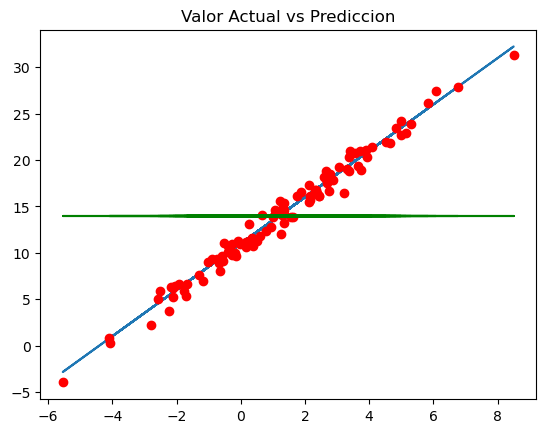

In [15]:
%matplotlib inline
plt.plot(x,y_pred)
plt.plot(x,y_act, "ro")
plt.plot(x,y_mean, "g")
plt.title("Valor Actual vs Prediccion")

## Como es la prediccion de buena?
* SST = SSD + SSR
* SST: Variabilidad de los datos con respecto de su media
* SSD: Diferencia entre los datos originales y las predicciones que el modelo no es capaz de explicar (errores que deberian seguir una distribucion normal)
* SSR: Diferencia entre la regresion y el valor del medio que el modelo busca explicar
* R2: SSR / SST, coeficiente de determinacion entre 0 y 1

In [16]:
data["SSR"] = (data["y_prediccion"] - np.mean(y_act)) ** 2
data["SSD"] = (data["y_prediccion"] - data["y_actual"]) ** 2
data["SST"] = (data["y_actual"] - np.mean(y_act)) ** 2

In [17]:
data.head()

,x,y_actual,y_prediccion,SSR,SSD,SST
0,-2.784464,2.226078,4.038840,98.555634,3.286104,137.834187
1,1.057198,14.594367,13.642994,0.104564,0.905109,0.394394
2,6.065803,27.407062,26.164508,148.794859,1.543939,180.652500
3,3.934497,20.344724,20.836241,47.195291,0.241589,40.683549
4,1.268400,14.731399,14.170999,0.041878,0.314048,0.585286


In [18]:
SSR = sum(data["SSR"])
SSD = sum(data["SSD"])
SST = sum(data["SST"])

In [19]:
SSR

3940.7866784908724

In [20]:
SSD

74.30790082769518

In [21]:
SST

4072.867026570136

In [22]:
R2 = SSR / SST

In [23]:
R2

0.9675706701894238

(array([ 8.,  9., 18., 12., 16., 18., 12.,  4.,  2.,  1.]),
 array([-1.53499451, -1.1278067 , -0.72061889, -0.31343108,  0.09375673,
         0.50094454,  0.90813235,  1.31532017,  1.72250798,  2.12969579,
         2.5368836 ]),
 <BarContainer object of 10 artists>)

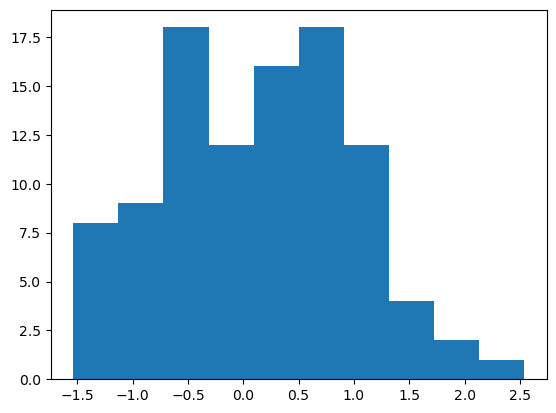

In [24]:
plt.hist((data["y_prediccion"] - data["y_actual"]))

### Obteniendo la recta de regresion
* y = a + b * x
* b = sum((xi - x_m) * (y_i - y_m)) / sum((xi - x_m) ^ 2)
* a = y_m - b * x_m

In [25]:
x_mean = np.mean(data["x"])
y_mean = np.mean(data["y_actual"])
x_mean, y_mean

(np.float64(1.2332015809711767), np.float64(13.966358548935256))

In [26]:
data["beta_n"] = (data["x"] - x_mean) * (data["y_actual"] - y_mean)
data["beta_d"] = (data["x"] - x_mean) ** 2

In [27]:
beta = sum(data["beta_n"]) / sum(data["beta_d"])

In [28]:
alpha = y_mean - beta * x_mean

In [29]:
alpha,beta

(np.float64(10.859683350600603), 2.5191949526111292)

El modelo lineal obtenido por regresion es: y = 10.859683350600603 + 10.859683350600603 * x

In [30]:
data["y_model"] = alpha + beta * data["x"]

In [31]:
data.head()

,x,y_actual,y_prediccion,SSR,SSD,SST,beta_n,beta_d,y_model
0,-2.784464,2.226078,4.038840,98.555634,3.286104,137.834187,47.168523,16.141638,3.845075
1,1.057198,14.594367,13.642994,0.104564,0.905109,0.394394,-0.110532,0.030977,13.522971
2,6.065803,27.407062,26.164508,148.794859,1.543939,180.652500,64.953566,23.354040,26.140625
3,3.934497,20.344724,20.836241,47.195291,0.241589,40.683549,17.229847,7.296995,20.771447
4,1.268400,14.731399,14.170999,0.041878,0.314048,0.585286,0.026928,0.001239,14.055029


In [32]:
SSR = sum((data["y_model"] - y_mean) ** 2)
SSD = sum((data["y_model"] - data["y_actual"]) ** 2)
SST = sum((data["y_actual"] - y_mean) ** 2)

In [33]:
SSR, SSD, SST

(4000.1519754117794, 72.71505115835495, 4072.867026570136)

In [35]:
R2 = SSR / SST
R2

0.9821464706105095

Text(0.5, 1.0, 'Valor Actual vs Prediccion')

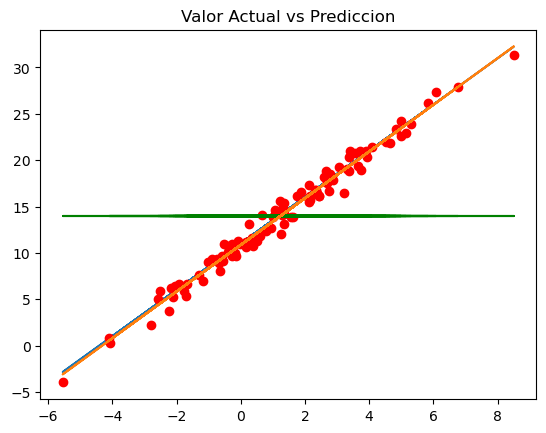

In [37]:
%matplotlib inline
y_mean = [np.mean(y_act) for i in range(1, len(x_list) + 1)]
plt.plot(data["x"], data["y_prediccion"])
plt.plot(data["x"], data["y_actual"], "ro")
plt.plot(data["x"], y_mean, "g")
plt.plot(data["x"], data["y_model"])
plt.title("Valor Actual vs Prediccion")

### Error estandar de los residuos RSE

In [41]:
RSE = np.sqrt(SSD/(len(data) - 2))
RSE

np.float64(0.8613885986837749)

In [42]:
np.mean(data["y_actual"])

np.float64(13.966358548935256)

In [43]:
RSE / np.mean((data["y_actual"]))

np.float64(0.06167596196715457)